# Recurrent vs. recurrent + attention: IMDB sentiment analysis

**The question.** Does adding additive (Bahdanau) attention to a recurrent model help it classify movie reviews as positive or negative?

**The plan.**
1. Load the IMDB dataset (50,000 movie reviews, half positive, half negative)
2. Turn text into numbers: tokenize, build a vocabulary, encode
3. Wrap it in a `Dataset` and `DataLoader` so the model gets padded batches
4. Build two models that share the **same** recurrent encoder:
   - **Recurrent only:** classify from the GRU's final hidden state
   - **Recurrent + attention:** classify from an attention-weighted average of *all* hidden states
5. Train both with the same training loop, the same data, and the same settings
6. Compare: accuracy, learning curves, accuracy by review length, and what attention looks at

This builds on `additive_attention_explained.ipynb`. The `AdditiveAttention` module below is the same one from that notebook.

## 0. Setup

All the settings live in one place, so both models are guaranteed to use the same ones.

**Why CPU?** Apple's GPU (`mps`) is great for big matrix multiplications, but a recurrent model processes words one at a time, and on this Mac the CPU measured about 2.5x faster for it. On a machine with an NVIDIA GPU, `cuda` is used automatically.

In [1]:
import random
import re
import time
import urllib.request
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence, pad_sequence
from torch.utils.data import DataLoader, Dataset

VOCAB_SIZE = 20_000      # keep the 20k most common words; everything else becomes <unk>
MAX_LEN = 256            # truncate reviews to this many tokens
EMBED_DIM = 128
HIDDEN_DIM = 128
ATTN_DIM = 64
DROPOUT = 0.3
BATCH_SIZE = 64
EPOCHS = 5
LEARNING_RATE = 1e-3
SEED = 0

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

device: cpu


## 1. Load the IMDB dataset

The [Large Movie Review Dataset](https://ai.stanford.edu/~amaas/data/sentiment/) (Maas et al., 2011) is 25,000 training reviews and 25,000 test reviews, each labeled positive or negative.

We load it from the Stanford NLP group's [Hugging Face mirror](https://huggingface.co/datasets/stanfordnlp/imdb): the same reviews and labels, stored as one Parquet file per split (a compact table format that `pandas` reads directly). Label `0` is negative, `1` is positive.

The first run downloads the two files (about 41 MB) into `notebooks/data/`, which git ignores. Later runs reuse them.

In [2]:
import pandas as pd

DATA_DIR = Path("data")
IMDB_URL = "https://huggingface.co/datasets/stanfordnlp/imdb/resolve/main/plain_text/{split}-00000-of-00001.parquet"

def load_split(split):
    path = DATA_DIR / f"imdb_{split}.parquet"
    if not path.exists():
        DATA_DIR.mkdir(exist_ok=True)
        print(f"downloading IMDB {split} split...")
        urllib.request.urlretrieve(IMDB_URL.format(split=split), path)
    table = pd.read_parquet(path)
    return table["text"].tolist(), table["label"].tolist()

train_texts, train_labels = load_split("train")
test_texts, test_labels = load_split("test")
print(f"{len(train_texts)} training reviews, {len(test_texts)} test reviews")
print(f"fraction positive in train: {np.mean(train_labels):.2f}")
print("\nexample:", train_texts[0][:300], "...")
print("label:", train_labels[0])

25000 training reviews, 25000 test reviews
fraction positive in train: 0.50

example: I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really h ...
label: 0


## 2. Text to numbers

A model can't read words, only numbers. Three steps:

1. **Tokenize:** split a review into lowercase words (and strip the `<br />` HTML tags IMDB reviews contain)
2. **Build a vocabulary** from the *training* set only: each of the 20k most common words gets an integer id. Two ids are reserved:
   - `0 = <pad>`: filler used to make reviews in a batch the same length
   - `1 = <unk>`: any word not in the vocabulary
3. **Encode:** replace each word with its id, and truncate to `MAX_LEN`

The vocabulary comes from training data only, so no information from the test set leaks into the model.

In [3]:
def tokenize(text):
    text = text.lower().replace("<br />", " ")
    return re.findall(r"[a-z0-9']+", text)

print(tokenize("This movie was GREAT!<br />Really, I loved it."))

word_counts = Counter(word for text in train_texts for word in tokenize(text))
id_to_word = ["<pad>", "<unk>"] + [word for word, _ in word_counts.most_common(VOCAB_SIZE - 2)]
word_to_id = {word: index for index, word in enumerate(id_to_word)}
PAD_ID, UNK_ID = 0, 1

def encode(text):
    ids = [word_to_id.get(word, UNK_ID) for word in tokenize(text)][:MAX_LEN]
    return ids or [UNK_ID]          # guard against an empty review

print(f"vocabulary size: {len(id_to_word)} (from {len(word_counts)} distinct training words)")
print("encoded:", encode("This movie was GREAT! Really, I loved it. Flibbertigibbet."))

['this', 'movie', 'was', 'great', 'really', 'i', 'loved', 'it']
vocabulary size: 20000 (from 87171 distinct training words)
encoded: [11, 17, 13, 85, 63, 10, 445, 9, 1]


How long are reviews? This matters: a recurrent model has to carry information across every word, so long reviews are harder for it. `MAX_LEN = 256` keeps most of each review while keeping training fast.

In [4]:
review_lengths = np.array([len(tokenize(text)) for text in train_texts])
print(f"median length: {np.median(review_lengths):.0f} tokens")
print(f"fraction longer than MAX_LEN={MAX_LEN}: {np.mean(review_lengths > MAX_LEN):.2f}")

median length: 174 tokens
fraction longer than MAX_LEN=256: 0.29


## 3. `Dataset` and `DataLoader`

**`Dataset`** answers two questions: how many examples are there (`__len__`), and what is example `i` (`__getitem__`).

**`DataLoader`** groups examples into batches and shuffles them each epoch. Reviews have different lengths, so we give it a `collate_fn` that pads every review in a batch to the length of the longest one, using `<pad> = 0`.

Each batch is `(token_ids, lengths, labels)`:
- `token_ids`: `(batch, longest_in_batch)`
- `lengths`: `(batch,)`, the real length of each review before padding. The models use it to ignore padding.
- `labels`: `(batch,)`, 0 or 1

We also hold out 5,000 training reviews as a **validation set**. We use it to pick the best epoch, and touch the test set only once at the end.

In [5]:
class ReviewDataset(Dataset):
    def __init__(self, texts, labels):
        self.token_ids = [torch.tensor(encode(text)) for text in texts]
        self.labels = labels

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        return self.token_ids[index], self.labels[index]

def collate_batch(batch):
    token_ids, labels = zip(*batch)
    lengths = torch.tensor([len(ids) for ids in token_ids])
    padded = pad_sequence(token_ids, batch_first=True, padding_value=PAD_ID)
    return padded, lengths, torch.tensor(labels, dtype=torch.float32)

set_seed(SEED)
shuffled = list(range(len(train_texts)))
random.shuffle(shuffled)
train_indices, val_indices = shuffled[:20_000], shuffled[20_000:]

train_dataset = ReviewDataset([train_texts[i] for i in train_indices], [train_labels[i] for i in train_indices])
val_dataset = ReviewDataset([train_texts[i] for i in val_indices], [train_labels[i] for i in val_indices])
test_dataset = ReviewDataset(test_texts, test_labels)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_batch)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, collate_fn=collate_batch)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, collate_fn=collate_batch)

token_ids, lengths, labels = next(iter(train_loader))
print("token_ids:", token_ids.shape, " lengths:", lengths[:8].tolist(), " labels:", labels[:8].tolist())
print(f"{len(train_dataset)} train / {len(val_dataset)} val / {len(test_dataset)} test")

token_ids: torch.Size([64, 256])  lengths: [169, 60, 140, 123, 256, 114, 230, 143]  labels: [1.0, 0.0, 0.0, 0.0, 0.0, 1.0, 1.0, 0.0]
20000 train / 5000 val / 25000 test


## 4. The models

### The shared encoder

Both models start the same way:
1. `nn.Embedding` turns each word id into a learned vector of size `EMBED_DIM`
2. `nn.GRU` reads the review left to right and produces a hidden state at **every** position (`encoder_states`) plus a final one (`last_hidden`)

**Packing.** Without care, the GRU would also read the `<pad>` tokens at the end of short reviews, and `last_hidden` would be the state *after the padding*. `pack_padded_sequence` tells the GRU each review's real length, so it stops at the last real word.

(A GRU is a simpler cousin of the LSTM: same idea of gates that decide what to remember, fewer parameters.)

In [6]:
class RecurrentEncoder(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=PAD_ID)
        self.rnn = nn.GRU(embed_dim, hidden_dim, batch_first=True)

    def forward(self, token_ids, lengths):
        embedded = self.embedding(token_ids)                                   # (batch, seq_len, embed_dim)
        packed = pack_padded_sequence(embedded, lengths.cpu(), batch_first=True, enforce_sorted=False)
        packed_states, last_hidden = self.rnn(packed)
        encoder_states, _ = pad_packed_sequence(packed_states, batch_first=True,
                                                total_length=token_ids.shape[1])  # (batch, seq_len, hidden_dim)
        return encoder_states, last_hidden.squeeze(0)                          # last_hidden: (batch, hidden_dim)

### Model A: recurrent only

Classify from `last_hidden`. The whole review has to be squeezed into that one vector, and by the end of a 250-word review the GRU may have partly forgotten the beginning.

The output is a single number (a **logit**): positive means "positive review", negative means "negative review". `BCEWithLogitsLoss` applies the sigmoid for us during training.

Following Professor McNeill's advice, every sub-network is created **inside `__init__`** rather than built outside and passed in.

In [7]:
class RecurrentClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, dropout):
        super().__init__()
        self.encoder = RecurrentEncoder(vocab_size, embed_dim, hidden_dim)
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden_dim, 1)

    def forward(self, token_ids, lengths):
        _, last_hidden = self.encoder(token_ids, lengths)
        logits = self.classifier(self.dropout(last_hidden)).squeeze(-1)        # (batch,)
        return logits, None                                                    # None: no attention weights

### Model B: recurrent + attention

Same encoder, but instead of using only `last_hidden`, we let attention build a weighted average of **all** the hidden states, so the classifier can look straight at the important words wherever they are.

How this maps onto the attention notebook:

| Attention notebook (translation) | Here (classification) |
|---|---|
| `decoder_state` (the query) | `last_hidden`, the GRU's summary of the review |
| `encoder_states` (keys and values) | the GRU's hidden state at every word |
| `padding_mask` | `True` for real words, `False` for `<pad>` |
| `context_vector` | the input to the classifier |

There is no decoder in sentiment analysis, so the query is the encoder's own summary. Attention then asks: *given the gist of this review, which words matter most?*

`AdditiveAttention` is copied unchanged from the first notebook.

In [8]:
class AdditiveAttention(nn.Module):
    def __init__(self, decoder_dim, encoder_dim, attn_dim):
        super().__init__()
        self.query_projection = nn.Linear(decoder_dim, attn_dim, bias=False)   # holds query_weights
        self.key_projection = nn.Linear(encoder_dim, attn_dim, bias=False)     # holds key_weights
        self.score_projection = nn.Linear(attn_dim, 1, bias=False)             # holds score_vector

    def forward(self, decoder_states, encoder_states, padding_mask):
        projected_query = self.query_projection(decoder_states)                # (batch, attn_dim)
        projected_keys = self.key_projection(encoder_states)                   # (batch, seq_len, attn_dim)
        hidden = torch.tanh(projected_query.unsqueeze(1) + projected_keys)     # (batch, seq_len, attn_dim)
        scores = self.score_projection(hidden).squeeze(-1)                     # (batch, seq_len)
        scores = scores.masked_fill(~padding_mask, float("-inf"))
        attention_weights = torch.softmax(scores, dim=1)
        context_vector = (attention_weights.unsqueeze(-1) * encoder_states).sum(dim=1)
        return context_vector, attention_weights


class AttentionClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, attn_dim, dropout):
        super().__init__()
        self.encoder = RecurrentEncoder(vocab_size, embed_dim, hidden_dim)
        self.attention = AdditiveAttention(hidden_dim, hidden_dim, attn_dim)
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden_dim, 1)

    def forward(self, token_ids, lengths):
        encoder_states, last_hidden = self.encoder(token_ids, lengths)
        positions = torch.arange(token_ids.shape[1], device=token_ids.device)
        padding_mask = positions.unsqueeze(0) < lengths.to(token_ids.device).unsqueeze(1)   # (batch, seq_len)
        context_vector, attention_weights = self.attention(last_hidden, encoder_states, padding_mask)
        logits = self.classifier(self.dropout(context_vector)).squeeze(-1)     # (batch,)
        return logits, attention_weights

Sanity check before training: push one batch through both models and check the shapes. Attention weights should sum to 1 for every review and be exactly 0 on padding.

In [9]:
recurrent_model = RecurrentClassifier(VOCAB_SIZE, EMBED_DIM, HIDDEN_DIM, DROPOUT)
attention_model = AttentionClassifier(VOCAB_SIZE, EMBED_DIM, HIDDEN_DIM, ATTN_DIM, DROPOUT)

logits, _ = recurrent_model(token_ids, lengths)
print("recurrent logits:", logits.shape)
logits, weights = attention_model(token_ids, lengths)
print("attention logits:", logits.shape, " weights:", weights.shape)

assert torch.allclose(weights.sum(dim=1), torch.ones(len(lengths)))
shortest = lengths.argmin()
assert (weights[shortest, lengths[shortest]:] == 0).all()
print("weights sum to 1 and padding gets 0 weight")

count_parameters = lambda model: sum(p.numel() for p in model.parameters())
print(f"\nparameters: recurrent {count_parameters(recurrent_model):,} | "
      f"attention {count_parameters(attention_model):,} "
      f"(+{count_parameters(attention_model) - count_parameters(recurrent_model):,} for attention)")

recurrent logits: torch.Size([64])
attention logits: torch.Size([64])  weights: torch.Size([64, 256])
weights sum to 1 and padding gets 0 weight

parameters: recurrent 2,659,201 | attention 2,675,649 (+16,448 for attention)


## 5. The training loop

This is the part PyTorch Lightning will later write for us. For each batch:

1. **Forward pass:** compute logits
2. **Loss:** how wrong were we? (`BCEWithLogitsLoss`, binary cross-entropy)
3. `optimizer.zero_grad()`: clear the previous batch's gradients (PyTorch adds them up otherwise)
4. `loss.backward()`: compute the gradient of the loss with respect to **every** weight, including the three attention weight matrices
5. `optimizer.step()`: nudge every weight a little in the direction that lowers the loss

That's the answer to "how are the attention parameters learned?": in the first notebook we set them by hand to identity matrices; here steps 4 and 5 learn them from data.

**Evaluation** is the same forward pass with two differences:
- `model.eval()` turns dropout off
- `torch.no_grad()` skips gradient bookkeeping, since we don't update anything

Gradient clipping (`clip_grad_norm_`) caps very large gradients, a standard safeguard for recurrent models.

In [10]:
loss_fn = nn.BCEWithLogitsLoss()

def train_one_epoch(model, loader, optimizer):
    model.train()
    total_loss, total_correct, total_count = 0.0, 0, 0
    for token_ids, lengths, labels in loader:
        token_ids, labels = token_ids.to(device), labels.to(device)
        logits, _ = model(token_ids, lengths)
        loss = loss_fn(logits, labels)

        optimizer.zero_grad()
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()

        total_loss += loss.item() * len(labels)
        total_correct += ((logits > 0) == (labels == 1)).sum().item()
        total_count += len(labels)
    return total_loss / total_count, total_correct / total_count

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    total_loss, total_correct, total_count = 0.0, 0, 0
    for token_ids, lengths, labels in loader:
        token_ids, labels = token_ids.to(device), labels.to(device)
        logits, _ = model(token_ids, lengths)
        total_loss += loss_fn(logits, labels).item() * len(labels)
        total_correct += ((logits > 0) == (labels == 1)).sum().item()
        total_count += len(labels)
    return total_loss / total_count, total_correct / total_count

def train_model(model, name):
    model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_val_acc, best_state = 0.0, None
    for epoch in range(1, EPOCHS + 1):
        start = time.time()
        train_loss, train_acc = train_one_epoch(model, train_loader, optimizer)
        val_loss, val_acc = evaluate(model, val_loader)
        for key, value in zip(history, (train_loss, train_acc, val_loss, val_acc)):
            history[key].append(value)
        if val_acc > best_val_acc:                       # keep the weights from the best epoch
            best_val_acc = val_acc
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        print(f"[{name}] epoch {epoch}: train loss {train_loss:.3f} acc {train_acc:.3f} | "
              f"val loss {val_loss:.3f} acc {val_acc:.3f} | {time.time() - start:.0f}s")
    model.load_state_dict(best_state)
    return history

## 6. Train both models

Same seed, same data order, same settings: the **only** difference between the two runs is the attention layer. This takes a while on a laptop CPU (roughly 10 minutes per model).

In [11]:
set_seed(SEED)
recurrent_model = RecurrentClassifier(VOCAB_SIZE, EMBED_DIM, HIDDEN_DIM, DROPOUT)
recurrent_history = train_model(recurrent_model, "recurrent")

[recurrent] epoch 1: train loss 0.627 acc 0.635 | val loss 0.521 acc 0.749 | 100s
[recurrent] epoch 2: train loss 0.443 acc 0.802 | val loss 0.399 acc 0.829 | 102s
[recurrent] epoch 3: train loss 0.304 acc 0.879 | val loss 0.325 acc 0.864 | 101s
[recurrent] epoch 4: train loss 0.213 acc 0.921 | val loss 0.334 acc 0.865 | 102s
[recurrent] epoch 5: train loss 0.140 acc 0.950 | val loss 0.357 acc 0.868 | 99s


In [12]:
set_seed(SEED)
attention_model = AttentionClassifier(VOCAB_SIZE, EMBED_DIM, HIDDEN_DIM, ATTN_DIM, DROPOUT)
attention_history = train_model(attention_model, "attention")

[attention] epoch 1: train loss 0.500 acc 0.746 | val loss 0.357 acc 0.839 | 115s
[attention] epoch 2: train loss 0.295 acc 0.877 | val loss 0.310 acc 0.865 | 123s
[attention] epoch 3: train loss 0.202 acc 0.923 | val loss 0.307 acc 0.876 | 124s
[attention] epoch 4: train loss 0.134 acc 0.951 | val loss 0.350 acc 0.869 | 126s
[attention] epoch 5: train loss 0.077 acc 0.976 | val loss 0.477 acc 0.856 | 121s


## 7. Compare

### Test accuracy

Each model uses its best epoch (by validation accuracy). This is the first and only time the test set is used.

In [13]:
results = {}
for name, model in [("recurrent", recurrent_model), ("recurrent + attention", attention_model)]:
    test_loss, test_acc = evaluate(model, test_loader)
    results[name] = test_acc
    print(f"{name:>22}: test accuracy {test_acc:.4f}  (test loss {test_loss:.3f})")

             recurrent: test accuracy 0.8570  (test loss 0.387)
 recurrent + attention: test accuracy 0.8686  (test loss 0.325)


### Learning curves

Training accuracy climbing while validation accuracy flattens or drops is **overfitting**: the model memorizing the training reviews instead of learning general patterns.

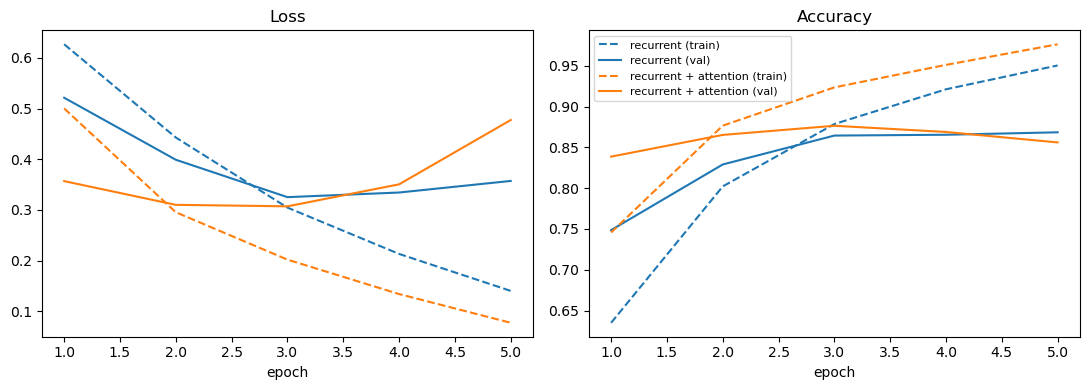

In [14]:
epochs = range(1, EPOCHS + 1)
figure, (loss_axis, acc_axis) = plt.subplots(1, 2, figsize=(11, 4))
for name, history, color in [("recurrent", recurrent_history, "tab:blue"),
                             ("recurrent + attention", attention_history, "tab:orange")]:
    loss_axis.plot(epochs, history["train_loss"], "--", color=color, label=f"{name} (train)")
    loss_axis.plot(epochs, history["val_loss"], "-", color=color, label=f"{name} (val)")
    acc_axis.plot(epochs, history["train_acc"], "--", color=color, label=f"{name} (train)")
    acc_axis.plot(epochs, history["val_acc"], "-", color=color, label=f"{name} (val)")
loss_axis.set(title="Loss", xlabel="epoch")
acc_axis.set(title="Accuracy", xlabel="epoch")
acc_axis.legend(fontsize=8)
plt.tight_layout()
plt.show()

### Accuracy by review length

The motivation for attention is that a recurrent model has to remember everything in its final hidden state, which should get harder as reviews get longer. If that's right, attention's advantage should grow with length.

In [15]:
@torch.no_grad()
def predictions_and_lengths(model, loader):
    model.eval()
    all_correct, all_lengths = [], []
    for token_ids, lengths, labels in loader:
        logits, _ = model(token_ids.to(device), lengths)
        all_correct.append(((logits > 0) == (labels.to(device) == 1)).cpu())
        all_lengths.append(lengths)
    return torch.cat(all_correct).numpy(), torch.cat(all_lengths).numpy()

recurrent_correct, test_lengths = predictions_and_lengths(recurrent_model, test_loader)
attention_correct, _ = predictions_and_lengths(attention_model, test_loader)

length_buckets = [(0, 100), (100, 200), (200, MAX_LEN)]
print(f"{'tokens':>12} | {'reviews':>7} | {'recurrent':>9} | {'+ attention':>11}")
for low, high in length_buckets:
    in_bucket = (test_lengths > low) & (test_lengths <= high)
    print(f"{f'{low + 1}-{high}':>12} | {in_bucket.sum():>7} | "
          f"{recurrent_correct[in_bucket].mean():>9.4f} | {attention_correct[in_bucket].mean():>11.4f}")

      tokens | reviews | recurrent | + attention
       1-100 |    3163 |    0.8811 |      0.8897
     101-200 |   11758 |    0.8808 |      0.8867
     201-256 |   10079 |    0.8215 |      0.8409


### What does attention look at?

A bonus of the attention model: its weights show which words it relied on. Darker highlight = more weight. If attention learned something sensible, the highlights should land on sentiment words like "brilliant", "waste" or "boring".

In [16]:
from html import escape
from IPython.display import HTML, display

@torch.no_grad()
def show_attention(text, true_label):
    attention_model.eval()
    ids = encode(text)
    logits, weights = attention_model(torch.tensor([ids], device=device), torch.tensor([len(ids)]))
    weights = weights[0].cpu().numpy()
    probability = torch.sigmoid(logits).item()
    words = [id_to_word[i] for i in ids]
    strength = weights / weights.max()
    spans = "".join(f'<span style="background: rgba(255,140,0,{s:.2f}); padding: 1px 2px">{escape(w)}</span> '
                    for w, s in zip(words, strength))
    verdict = "positive" if probability > 0.5 else "negative"
    top_words = [words[i] for i in np.argsort(weights)[::-1][:8]]
    display(HTML(f"<p><b>true: {'positive' if true_label else 'negative'} | predicted: {verdict} "
                 f"({probability:.2f})</b><br>top words: {', '.join(top_words)}</p>"
                 f"<p style='line-height: 1.8'>{spans}</p><hr>"))

random.seed(1)
for index in random.sample(range(len(test_texts)), 3):
    show_attention(test_texts[index], test_labels[index])

Try your own:

In [17]:
show_attention("The acting was wooden and the plot made no sense, but the soundtrack was "
               "absolutely wonderful. Still, I would not watch it again.", 0)